In [1]:
import numpy as np
from scipy.optimize import root
from scipy.special import zeta
n, gamma, kmin = 100, 2.5, 1
# discrete power law P(k) = k^-gamma / Z on k = kmin..n-1
ks = np.arange(kmin, n)
P = ks**-gamma; P /= P.sum()
cdf = np.cumsum(P)
# target expected degrees: quantiles at (r-0.5)/n
u = (np.arange(1, n+1) - 0.5) / n
target = ks[np.searchsorted(cdf, u)].astype(float)
print("target degrees (sorted desc):", target[::-1].astype(int).tolist())
print("sum", target.sum(), "mean", target.mean(), " P(k) mean", (ks*P).sum())
from collections import Counter; print(sorted(Counter(target.astype(int)).items()))
def expdeg(th):
    T = th[:,None] + th[None,:]
    p = 1/(np.exp(T)+1); np.fill_diagonal(p, 0); return p
def F(th): return expdeg(th).sum(1) - target
th0 = np.log(np.sqrt(target.sum())/target)   # sparse-limit initial guess
sol = root(F, th0, method='hybr', tol=1e-12)
th = sol.x
print("converged", sol.success, "max resid", np.abs(F(th)).max())
# group by target degree
for k in sorted(set(target)):
    i = np.where(target==k)[0][0]
    print(f"k*={int(k):3d}  theta={th[i]: .4f}  x=e^-theta={np.exp(-th[i]):.4f}  count={int((target==k).sum())}")
p = expdeg(th)
print("max p_ij", p.max(), " sparse approx p=x_i x_j max:", (np.outer(np.exp(-th0),np.exp(-th0))*(1-np.eye(n))).max())
# sample and compare realized degree distribution
rng = np.random.default_rng(0)
iu = np.triu_indices(n,1)
deg_all = []
for s in range(2000):
    A = np.zeros((n,n)); A[iu] = rng.random(len(iu[0])) < p[iu]; A = A + A.T
    deg_all.append(A.sum(1))
deg_all = np.array(deg_all)
print("sampled mean deg per vertex vs target (max err)", np.abs(deg_all.mean(0)-target).max())
d = deg_all.ravel(); vals, cnts = np.unique(d, return_counts=True)
emp = dict(zip(vals.astype(int), cnts/len(d)))
for k in [0,1,2,3,4,5,8,10,15,20]:
    print(k, round(emp.get(k,0),4), round(P[k-kmin],4) if k>=kmin else '-')
# log-likelihood of an example graph: entropy
H = -(p[iu]*np.log(p[iu]) + (1-p[iu])*np.log(1-p[iu])).sum()
print("ensemble entropy (nats)", H)

target degrees (sorted desc): [20, 10, 7, 6, 5, 4, 4, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
sum 172.0 mean 1.72  P(k) mean 1.7988112258800704
[(np.int64(1), 75), (np.int64(2), 13), (np.int64(3), 5), (np.int64(4), 2), (np.int64(5), 1), (np.int64(6), 1), (np.int64(7), 1), (np.int64(10), 1), (np.int64(20), 1)]
converged True max resid 5.115907697472721e-13
k*=  1  theta= 2.6171  x=e^-theta=0.0730  count=75
k*=  2  theta= 1.8801  x=e^-theta=0.1526  count=13
k*=  3  theta= 1.4333  x=e^-theta=0.2385  count=5
k*=  4  theta= 1.1066  x=e^-theta=0.3307  count=2
k*=  5  theta= 0.8467  x=e^-theta=0.4288  count=1
k*=  6  theta= 0.6300  x=e^-theta=0.5326  count=1
k*=  7  theta= 0.4438  x=e^-theta=0.6416  count=1
k*= 10  theta= 0.0039  x=e^-theta=0.9961  count=1
k

In [2]:
"""Option B: hidden-field (rho(theta)) ensemble, Park & Newman Eqs. (25)-(27), exact fermionic form."""
import numpy as np
from scipy.stats import binom
from scipy.optimize import brentq

n, gamma = 100, 2.5
ks = np.arange(0, n)                       # possible degrees 0..99
t = np.zeros(n); t[1:] = ks[1:]**-gamma; t /= t.sum()   # target P(k), k=1..99
print("target mean degree", (ks*t).sum())

def solve_theta(q_target, w, iters=200000, tol=1e-13):
    """Find theta_m so that q_m = sum_m' w_m' / (exp(theta_m+theta_m')+1)  (continuum Eq. 27 / (n-1)).
    Fixed-point iteration on fugacities x = e^-theta:  x_m <- q_m / sum_m' w_m' x_m' / (1 + x_m x_m')."""
    x = q_target / np.sqrt((w*q_target).sum())        # sparse-limit start
    for _ in range(iters):
        x_new = q_target / (w[None, :] * x[None, :] / (1 + x[:, None]*x[None, :])).sum(1)
        x_new = 0.5*x + 0.5*x_new
        if np.abs(x_new/x - 1).max() < tol: x = x_new; break
        x = x_new
    th = -np.log(x)
    res = np.abs((w[None, :] / (np.exp(th[:, None] + th[None, :]) + 1)).sum(1) - q_target).max()
    return th, res

def realized(q, w):
    """Exact degree distribution: P(k) = sum_m w_m Binom(k; n-1, q_m)."""
    return (w[:, None] * binom.pmf(ks[None, :], n - 1, q[:, None])).sum(0)

# ---------------- B-i: expected degrees kappa ~ continuous power law ----------------
# kappa in [kmin, kmax] with density ~ kappa^-2.5; kmax = 50, kmin fixed by <kappa> = target mean
M = 1000
kmax = 50.0
mean_t = (ks*t).sum()
def pareto_mean(a):
    # mean of density ~ x^-2.5 on [a, kmax]
    num = (a**-0.5 - kmax**-0.5) / 0.5
    den = (a**-1.5 - kmax**-1.5) / 1.5
    return num/den
kmin = brentq(lambda a: pareto_mean(a) - mean_t, 0.05, 5)
u = (np.arange(M) + 0.5) / M
# inverse CDF of truncated Pareto(1.5)
kap = (kmin**-1.5 - u*(kmin**-1.5 - kmax**-1.5))**(-1/1.5)
w = np.full(M, 1.0/M)
q = kap / (n - 1)
th, res = solve_theta(q, w)
P_Bi = realized(q, w)
print(f"\nB-i: kappa_min={kmin:.4f}, kappa_max={kmax}, theta solve residual {res:.1e}")
print("     theta range", th.min(), th.max())
for kk in [1, 2, 5, 10, 20, 40]:
    i = np.argmin(np.abs(kap - kk)); print(f"     kappa={kap[i]:6.2f}  theta={th[i]: .4f}  x={np.exp(-th[i]):.4f}")
print("     P(0) =", P_Bi[0], " mean =", (ks*P_Bi).sum())

# ---------------- B-ii: choose rho so realized P(k) is as close to target as possible -----
# mixture of Binomial(n-1, q) over a grid of q; EM maximises sum_k t_k log P_k (min KL(t||P))
qg = np.concatenate([np.geomspace(1e-4, 0.6, 400)])
B = binom.pmf(ks[None, :], n - 1, qg[:, None])          # components
wg = np.full(len(qg), 1/len(qg))
for it in range(20000):
    P = wg @ B
    r = (wg[:, None] * B) / np.maximum(P[None, :], 1e-300)   # responsibilities
    wg_new = (r * t[None, :]).sum(1)
    if np.abs(wg_new - wg).max() < 1e-12: break
    wg = wg_new
P_Bii = wg @ B
keep = wg > 1e-6
qk, wk = qg[keep], wg[keep] / wg[keep].sum()
th2, res2 = solve_theta(qk, wk)
print(f"\nB-ii: EM iterations {it}, support points {keep.sum()}, theta residual {res2:.1e}")
print("     P(0) =", P_Bii[0], " mean =", (ks*P_Bii).sum(), " KL(t||P) =", (t[1:]*np.log(t[1:]/P_Bii[1:])).sum())
order = np.argsort(qk)
for i in order:
    print(f"     weight={wk[i]:.4f}  kappa=(n-1)q={(n-1)*qk[i]:7.3f}  theta={th2[i]: .4f}")

# Jensen lower bound on P(0) for ANY rho with this mean
qbar = mean_t/(n-1)
print("\nJensen bound P(0) >= (1-<k>/(n-1))^(n-1) =", (1-qbar)**(n-1))

print("\n k   target   B-i      B-ii")
for kk in [0,1,2,3,4,5,6,8,10,15,20,30,50]:
    print(f"{kk:3d}  {t[kk]:.4f}  {P_Bi[kk]:.4f}  {P_Bii[kk]:.4f}")
np.savez("option_b.npz", t=t, P_Bi=P_Bi, P_Bii=P_Bii, kap=kap, th=th, qk=qk, wk=wk, th2=th2)

target mean degree 1.7988112258800706

B-i: kappa_min=0.6775, kappa_max=50.0, theta solve residual 6.2e-14
     theta range -2.029579107304027 3.0497835217991023
     kappa=  1.00  theta= 2.6429  x=0.0712
     kappa=  2.00  theta= 1.9025  x=0.1492
     kappa=  4.99  theta= 0.8837  x=0.4132
     kappa=  9.85  theta= 0.0753  x=0.9275
     kappa= 20.36  theta=-0.8787  x=2.4077
     kappa= 41.63  theta=-2.0296  x=7.6109
     P(0) = 0.30147764655335707  mean = 1.797971574897141

B-ii: EM iterations 19999, support points 26, theta residual 9.2e-14
     P(0) = 0.24279573935656312  mean = 1.7919248545155164  KL(t||P) = 0.48023804887411553
     weight=0.0000  kappa=(n-1)q=  1.308  theta= 2.3480
     weight=0.0625  kappa=(n-1)q=  1.337  theta= 2.3246
     weight=0.8809  kappa=(n-1)q=  1.367  theta= 2.3012
     weight=0.0165  kappa=(n-1)q=  1.397  theta= 2.2777
     weight=0.0001  kappa=(n-1)q=  7.324  theta= 0.4326
     weight=0.0224  kappa=(n-1)q=  7.486  theta= 0.4071
     weight=0.0070  kappa

In [3]:
"""Option C: maximum-entropy ensemble with <N_k> = n P(k) for every k.
   H(G) = sum_k lambda_k N_k(G) = sum_i lambda_{k_i(G)}.
   Step 1: saddle-point (Hubbard-Stratonovich) estimate of lambda_k.
   Step 2: Monte Carlo + iterative scaling to make <N_k> match exactly."""
import numpy as np, subprocess, sys
from concurrent.futures import ThreadPoolExecutor
from scipy.special import gammaln

n, gamma = 100, 2.5
MMIN, MMAX = 70, 110                             # graph set: MMIN <= m <= MMAX (removes the dense phase)
ks = np.arange(n)
t = np.zeros(n); t[1:] = ks[1:]**-gamma; t /= t.sum()
target = n * t                                   # <N_k> targets
kbar = (ks*t).sum()

# ---- Step 1: saddle point  P(k) = e^{-lam_k} X^k / k! / A(X),  X*^2 = n <k>
X = np.sqrt(n*kbar)
lam0 = np.full(n, np.inf)
lam0[1:] = -np.log(t[1:]) - gammaln(ks[1:]+1) + ks[1:]*np.log(X)
lam0[1:] -= lam0[1]                              # gauge: lambda_1 = 0
print(f"<k> = {kbar:.4f},  X* = sqrt(n<k>) = {X:.4f}")

def run(lam, sweeps, burn, seeds):
    def one(seed):
        inp = f"{n} {sweeps} {burn} {seed} {MMIN} {MMAX}\n" + " ".join(f"{v:.12g}" for v in lam[1:]) + "\n"
        out = subprocess.run(["./mc_option_c"], input=inp, capture_output=True, text=True).stdout.split("\n")
        Nk = np.array([float(v) for v in out[:n]]); extra = np.array([float(v) for v in out[n].split()])
        return Nk, extra
    with ThreadPoolExecutor(len(seeds)) as ex:
        res = list(ex.map(one, seeds))
    Nk = np.mean([r[0] for r in res], 0); extra = np.mean([r[1] for r in res], 0)
    se = np.std([r[0] for r in res], 0) / np.sqrt(len(seeds))
    return Nk, se, extra

seeds = list(range(1, 9))
Nk0, _, ex0 = run(lam0, 4000, 500, seeds)
print("\nsaddle-point lambdas, MC check:")
for k in [1,2,3,4,5,10,20]: print(f"  k={k:2d} target {target[k]:.4f}  MC {Nk0[k]:.4f}")

lam = lam0.copy()
delta = 1e-4
for it in range(60):
    sweeps = 2000 if it < 30 else (10000 if it < 50 else 40000)
    Nk, se, ex = run(lam, sweeps, 300, [s + 100*it for s in seeds])
    step = np.log((Nk[1:] + delta) / (target[1:] + delta))
    lam[1:] += 0.5 * np.clip(step, -2.0, 2.0)
    lam[1:] -= lam[1]
    err = np.abs(Nk[1:31] - target[1:31]) / target[1:31]
    if it % 5 == 4 or it < 3:
        print(f"iter {it:2d}  max rel err k<=30: {err.max():.4f}   <m>={ex[2]:.2f}  <kmax>={ex[4]:.2f}")

Nk, se, ex = run(lam, 100000, 1000, [s + 9999 for s in seeds])
print("\nfinal check (8 x 1e5 sweeps):")
print("  k   target <N_k>   MC <N_k>  (s.e.)    lambda_k   saddle lambda_k")
for k in [1,2,3,4,5,6,7,8,10,12,15,20,25,30,40,50]:
    print(f"{k:3d}   {target[k]:9.5f}  {Nk[k]:9.5f} ({se[k]:.5f})  {lam[k]:9.4f}  {lam0[k]:9.4f}")
print(f"  <N_0> = {Nk[0]}")
print(f"  <N_1> = {ex[0]:.3f}, Var(N_1) = {ex[1]:.3f};  <m> = {ex[2]:.3f}, Var(m) = {ex[3]:.3f};  <k_max> = {ex[4]:.2f}")
print(f"  target <m> = n<k>/2 = {n*kbar/2:.3f}")
np.savez("option_c.npz", lam=lam, lam0=lam0, Nk=Nk, target=target)

<k> = 1.7988,  X* = sqrt(n<k>) = 13.4120


FileNotFoundError: [Errno 2] No such file or directory: './mc_option_c'

N = 9900, p = 0.020202, theta = 3.8816
graph 1: m = 193, log P(G) = -951.19


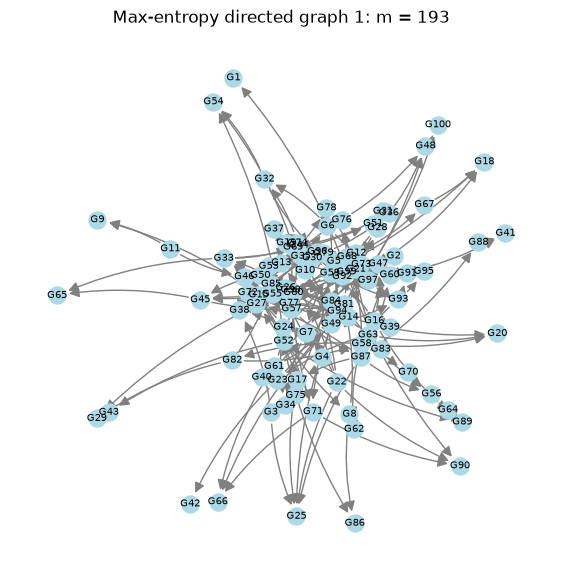

graph 2: m = 200, log P(G) = -978.36


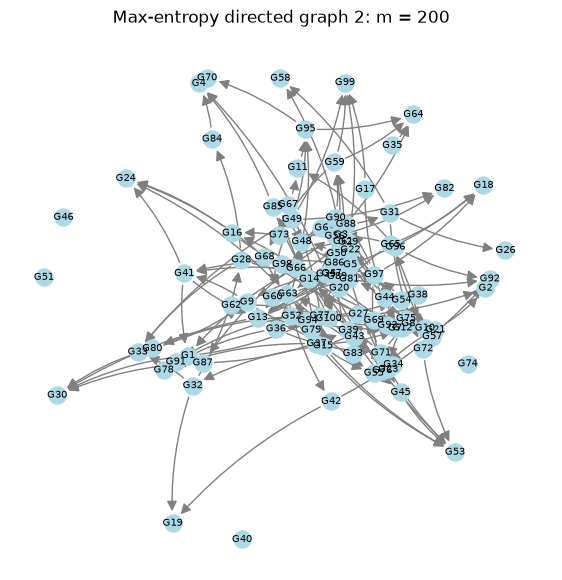

graph 3: m = 188, log P(G) = -931.78


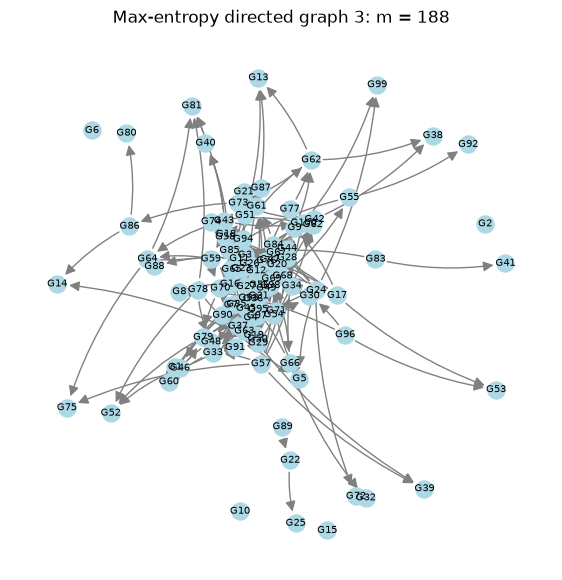

In [4]:
"""
Maximum-entropy directed graphs on n = 100 nodes, given only <m> = 200.

Derivation (Park & Newman, Sec. III A, directed version):
  Maximise S = -sum_G P(G) ln P(G)  subject to  sum_G P(G) = 1,  sum_G P(G) m(G) = <m>
  =>  P(G) = exp(-theta * m(G)) / Z,   m(G) = sum_{i != j} sigma_ij
  H is a sum over the N = n(n-1) ordered pairs, so Z = (1 + e^{-theta})^N
  =>  each directed edge i -> j exists independently with p = 1 / (e^theta + 1)
  =>  P(G) = p^m (1-p)^(N-m)
  Constraint <m> = N p  =>  p = 200 / 9900,  theta = ln((1-p)/p)
"""
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

N_NODES = 100
EXPECTED_EDGES = 200
N_GRAPHS = 3

n_pairs = N_NODES * (N_NODES - 1)          # ordered pairs (i, j), i != j
p = EXPECTED_EDGES / n_pairs
theta = np.log((1 - p) / p)
print(f"N = {n_pairs}, p = {p:.6f}, theta = {theta:.4f}")


def sample_maxent_digraph(n, p, rng):
    """Exact draw from P(G) = exp(-theta m(G)) / Z over simple directed graphs."""
    A = rng.random((n, n)) < p             # one coin per ordered pair
    np.fill_diagonal(A, False)             # no self-loops
    names = [f"G{i}" for i in range(1, n + 1)]
    G = nx.DiGraph()
    G.add_nodes_from(names)
    rows, cols = np.nonzero(A)
    G.add_edges_from((names[i], names[j]) for i, j in zip(rows, cols))
    return G


def log_prob(G):
    m = G.number_of_edges()
    return m * np.log(p) + (n_pairs - m) * np.log1p(-p)


rng = np.random.default_rng()              # put a number in here, e.g. default_rng(1), for reproducible graphs

for s in range(1, N_GRAPHS + 1):
    G = sample_maxent_digraph(N_NODES, p, rng)
    print(f"graph {s}: m = {G.number_of_edges()}, log P(G) = {log_prob(G):.2f}")

    # plot
    fig, ax = plt.subplots(figsize=(7, 7))
    pos = nx.spring_layout(G, seed=42)  # fixed seed for reproducible layout

    nx.draw_networkx_nodes(G, pos, node_color="lightblue", node_size=150, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=7, ax=ax)
    nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True,
                           arrowsize=15, connectionstyle="arc3,rad=0.1", ax=ax)
    ax.set_title(f"Max-entropy directed graph {s}: m = {G.number_of_edges()}")
    ax.axis("off")
    plt.show()

N = 9900, p = 0.020202, theta = 3.8816
graph 1: m = 205, log P(G) = -997.77, isolated = 2


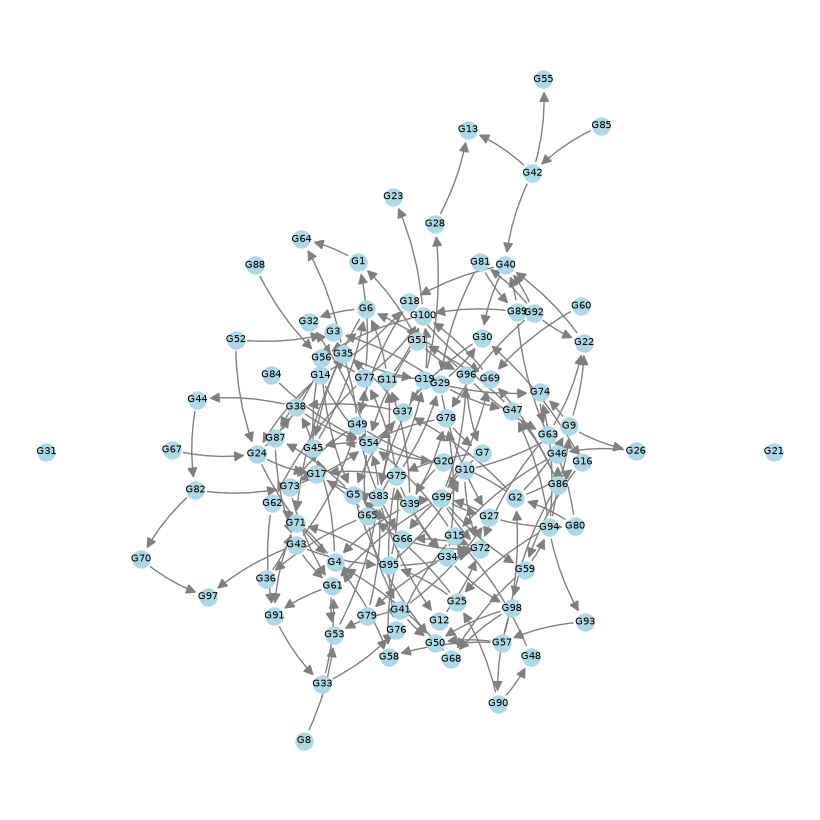

graph 2: m = 194, log P(G) = -955.07, isolated = 5


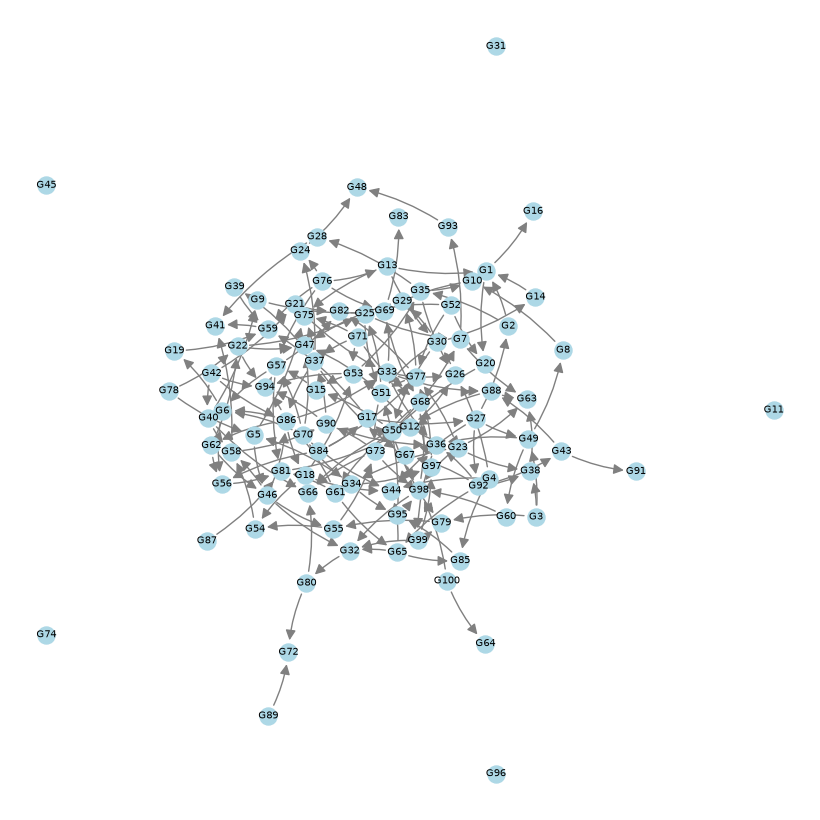

graph 3: m = 223, log P(G) = -1067.64, isolated = 0


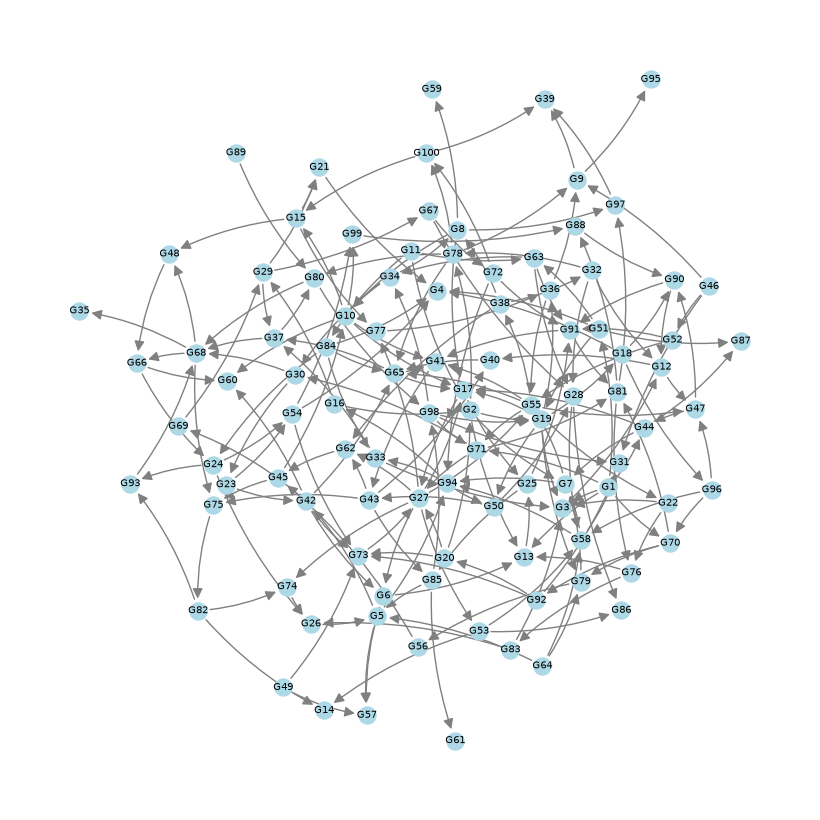

In [14]:
"""
Maximum-entropy directed graphs on n = 100 nodes, given only <m> = 200.

Derivation (Park & Newman, Sec. III A, directed version):
  Maximise S = -sum_G P(G) ln P(G)  subject to  sum_G P(G) = 1,  sum_G P(G) m(G) = <m>
  =>  P(G) = exp(-theta * m(G)) / Z,   m(G) = sum_{i != j} sigma_ij
  H is a sum over the N = n(n-1) ordered pairs, so Z = (1 + e^{-theta})^N
  =>  each directed edge i -> j exists independently with p = 1 / (e^theta + 1)
  =>  P(G) = p^m (1-p)^(N-m)
  Constraint <m> = N p  =>  p = 200 / 9900,  theta = ln((1-p)/p)
"""
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

N_NODES = 100
EXPECTED_EDGES = 200
N_GRAPHS = 3

n_pairs = N_NODES * (N_NODES - 1)          # ordered pairs (i, j), i != j
p = EXPECTED_EDGES / n_pairs
theta = np.log((1 - p) / p)
print(f"N = {n_pairs}, p = {p:.6f}, theta = {theta:.4f}")


def sample_maxent_digraph(n, p, rng):
    """Exact draw from P(G) = exp(-theta m(G)) / Z over simple directed graphs."""
    A = rng.random((n, n)) < p             # one coin per ordered pair
    np.fill_diagonal(A, False)             # no self-loops
    names = [f"G{i}" for i in range(1, n + 1)]
    G = nx.DiGraph()
    G.add_nodes_from(names)
    rows, cols = np.nonzero(A)
    G.add_edges_from((names[i], names[j]) for i, j in zip(rows, cols))
    return G


def log_prob(G):
    m = G.number_of_edges()
    return m * np.log(p) + (n_pairs - m) * np.log1p(-p)


def readable_layout(G, ring_radius=1.25):
    """Kamada-Kawai for the largest connected piece; small pieces and isolated nodes on an outer ring."""
    U = G.to_undirected()
    comps = sorted(nx.connected_components(U), key=len, reverse=True)
    pos = nx.kamada_kawai_layout(U.subgraph(comps[0]))
    small = comps[1:]
    for c, a in zip(small, np.linspace(0, 2 * np.pi, len(small), endpoint=False)):
        centre = ring_radius * np.array([np.cos(a), np.sin(a)])
        if len(c) == 1:
            pos[next(iter(c))] = centre
        else:                                # keep a small piece together around its ring spot
            sub = nx.kamada_kawai_layout(U.subgraph(c))
            for v, xy in sub.items():
                pos[v] = centre + 0.12 * xy
    return pos


rng = np.random.default_rng()              # new random graphs every run

for s in range(1, N_GRAPHS + 1):
    G = sample_maxent_digraph(N_NODES, p, rng)
    print(f"graph {s}: m = {G.number_of_edges()}, log P(G) = {log_prob(G):.2f}, "
          f"isolated = {nx.number_of_isolates(G)}")

    # plot
    fig, ax = plt.subplots(figsize=(8, 8))
    fig.tight_layout()
    pos = readable_layout(G)

    nx.draw_networkx_nodes(G, pos, node_color="lightblue", node_size=150, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=7, ax=ax)
    nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True,
                           arrowsize=15, connectionstyle="arc3,rad=0.1", ax=ax)
    ax.axis("off")
    plt.tight_layout(pad=0.0)
    plt.show()